# Projeto de Deep Learning — 04. Rede neural multiclasse (MLP)

Mesma formulação, divisão e validação cruzada do notebook 03: alvo com 6 classes (não faliu;
faliu no ano 1, …, 5 depois do balanço), treino 80% / teste 20% estratificados, CV estratificada de 5 folds no
treino, critério de escolha = **PR-AUC média dos anos 1 a 5** (cada ano exato contra o resto). Entradas: os 63
indicadores com faltantes imputados pela mediana do treino (nenhuma variável nova); redução obrigatória (Pearson + VIF
ou PCA 95%). O código da rede e dos testes estatísticos está nas primeiras células.

**Roteiro**
1. Arquitetura e treino.
2. **Pré-processamento**, um fator por vez (escala → redução → desbalanceamento), com a MLP base.
3. **Busca aleatória de hiperparâmetros**: camadas, neurônios, *dropout*, taxa de aprendizado, *weight decay*, lote.
4. **Treino longo**: mais épocas (até 5.000), agendas da taxa de aprendizado e regularização mais forte, com curvas de
   aprendizado.
5. **Seleção robusta**: os melhores candidatos são reavaliados com **5 sementes** e **CV repetida 3 × 5 folds**
   (15 folds, 3 divisões diferentes do treino). A escolha final usa essa média; testes pareados (t corrigido de
   Nadeau-Bengio e *bootstrap* pareado, com correção de Holm) dizem se a diferença para cada candidato é real.
6. **Modelo final** (média de 5 sementes em todo o treino) e avaliação única no teste.
7. Custo computacional.

Até a seção 4, cada configuração é avaliada com **1 semente** na divisão principal da CV (rápido, mas com ruído de
semente de cerca de 0,005 na PR-AUC média). A seção 5 existe justamente para que a escolha final não dependa desse
ruído.

Cada validação cruzada fica guardada em `resultados/cache_mlp/` (identificada pelo conteúdo: configuração, folds e
semente). Rodar o notebook de novo reaproveita o que já foi calculado.

## Funções do projeto

As mesmas funções aparecem no início dos notebooks 03 a 06, para cada um rodar sozinho.

**Dados, pré-processamento e métricas.** Funções compartilhadas pelos notebooks 03, 04 e 05 (formulação multiclasse). Alvo multiclasse ---------------- Cada linha da base é um balanço. O arquivo `kyear.arff` traz balanços tirados (6 - k) anos antes do desfecho.   y = 0        se a empresa não faliu no período observado   y = h ∈ {1,…,5}   se a empresa faliu h anos depois daquele balanço (h = 6 - k) Interpretação: P(y = h) é a probabilidade de a empresa falir no ano h depois do balanço (ano exato). Cada ano é avaliado como um problema "um contra o resto". A pergunta "faliu em algum dos 5 anos?" usa 1 - P(y = 0). Pré-processamento: só os 63 indicadores originais (X37 descartado, ~44% de faltantes); faltantes imputados pela mediana do treino; nenhuma variável nova é criada. A redução de dimensão é obrigatória: filtro de correlação + VIF ou PCA, com cortes fixos. Suposição (limitação): as empresas ativas são tratadas como "não falha em nenhum horizonte", embora só se saiba que não faliram dentro do período observado (censura). O arquivo de origem NÃO entra como variável: para as falidas ele determina a classe (vazamento).

In [1]:
from pathlib import Path
import json
import os
import zipfile
import warnings

os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count()))
warnings.filterwarnings('ignore', message='.*physical cores.*')

import numpy as np
import pandas as pd
from scipy.io import arff

from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import QuantileTransformer, RobustScaler, StandardScaler

set_config(transform_output='pandas')

RAPIDO = os.environ.get('RAPIDO') == '1'  # teste rápido do código (poucas configurações, poucas épocas)
SEMENTE = 42
N_FOLDS = 2 if RAPIDO else 5
REPETICOES = 2 if RAPIDO else 3   # repetições da CV (com outras divisões) na seleção robusta e nos testes
URL_DADOS = 'https://archive.ics.uci.edu/static/public/365/polish+companies+bankruptcy+data.zip'
FPR_ALVO = 0.05
CLASSES = [0, 1, 2, 3, 4, 5]
HORIZONTES = [1, 2, 3, 4, 5]
NOME_CLASSE = {0: 'não faliu', 1: 'faliu no ano 1', 2: 'faliu no ano 2', 3: 'faliu no ano 3',
               4: 'faliu no ano 4', 5: 'faliu no ano 5'}
VARS = [f'X{i}' for i in range(1, 65) if i != 37]  # X37 tem ~44% de faltantes (notebook 02)

ESCALAS = ['padronização', 'robusta', 'winsor + padronização', 'quantis (normal)']
SELECOES = ['corr + VIF', 'PCA 95%']  # redução obrigatória, cortes fixos (|r| > 0,8 e VIF ≥ 5; 95% da variância)
BALANCOS = ['nenhum', 'pesos', 'oversampling', 'SMOTE']

# Estilo dos gráficos (o mesmo dos notebooks anteriores)
TINTA, TINTA2, MUDO, GRADE, EIXO = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
ESTILO = {
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': EIXO, 'axes.labelcolor': TINTA2, 'axes.titlecolor': TINTA, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': MUDO, 'ytick.color': MUDO, 'text.color': TINTA2, 'legend.frameon': False,
    'figure.dpi': 110, 'lines.linewidth': 2, 'font.size': 10,
}
COR = {'Regressão logística': '#2a78d6', 'MLP': '#eb6834'}
COR_H = dict(zip(HORIZONTES, ['#104281', '#1c5cab', '#2a78d6', '#5598e7', '#86b6ef']))


# ----------------------------------------------------------------------------------------------------------------
# Dados
# ----------------------------------------------------------------------------------------------------------------
def carregar(pasta='dados'):
    pasta = Path(pasta)
    arquivos = {k: pasta / f'{k}year.arff' for k in range(1, 6)}
    if not all(p.exists() for p in arquivos.values()):
        zip_ = pasta / 'polish+companies+bankruptcy+data.zip'
        if not zip_.exists():  # baixa da UCI na primeira execução
            import urllib.request
            pasta.mkdir(parents=True, exist_ok=True)
            urllib.request.urlretrieve(URL_DADOS, zip_)
        with zipfile.ZipFile(zip_) as z:
            z.extractall(pasta)
    partes = []
    for k, p in arquivos.items():
        registros, _ = arff.loadarff(p)
        d = pd.DataFrame(registros)
        d.columns = [c.replace('Attr', 'X') for c in d.columns]
        d['class'] = d['class'].str.decode('utf-8').astype(int)
        partes.append(d.drop_duplicates().assign(arquivo=k))
    df = pd.concat(partes, ignore_index=True)
    df[VARS] = df[VARS].replace([np.inf, -np.inf], np.nan)
    df['y'] = np.where(df['class'] == 1, 6 - df['arquivo'], 0).astype(int)
    return df


def dividir(df, frac_teste=0.20):
    """Treino/teste estratificado pela classe multiclasse (que já inclui o horizonte das falidas)."""
    tr, te = train_test_split(df, test_size=frac_teste, stratify=df['y'], random_state=SEMENTE)
    return tr.reset_index(drop=True), te.reset_index(drop=True)


def folds(y, n=5, repeticao=0):
    """Folds estratificados da CV. repeticao = 0 é a divisão usada em todas as escolhas; repetições 1, 2, … sorteiam
    outras divisões (CV repetida), usadas só na seleção robusta e nos testes estatísticos."""
    return list(StratifiedKFold(n, shuffle=True, random_state=SEMENTE + repeticao).split(np.zeros(len(y)), y))


# ----------------------------------------------------------------------------------------------------------------
# Pré-processamento
# ----------------------------------------------------------------------------------------------------------------
class Winsorizador(BaseEstimator, TransformerMixin):
    """Corta cada coluna nos percentis [inferior, superior] aprendidos no fit."""

    def __init__(self, inferior=0.01, superior=0.99):
        self.inferior, self.superior = inferior, superior

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lim_inf_, self.lim_sup_ = X.quantile(self.inferior), X.quantile(self.superior)
        return self

    def transform(self, X):
        return pd.DataFrame(X).clip(self.lim_inf_, self.lim_sup_, axis=1)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.lim_inf_.index, dtype=object)


def vif(X):
    """VIF_j = j-ésimo elemento da diagonal da inversa da matriz de correlação (= 1 / (1 - R²_j))."""
    r = np.corrcoef(np.asarray(X, dtype=float), rowvar=False)
    return pd.Series(np.diag(np.linalg.pinv(r)), index=X.columns)


class FiltroCorrVIF(BaseEstimator, TransformerMixin):
    """Corte de correlação de Pearson (|r| > limiar_corr; fica a variável de maior |AUC - 0,5|) seguido de VIF
    iterativo (remove a de maior VIF até todas < limiar_vif). Mesmo critério do notebook 03 original."""

    def __init__(self, limiar_corr=0.80, limiar_vif=5.0):
        self.limiar_corr, self.limiar_vif = limiar_corr, limiar_vif

    def fit(self, X, y):
        X = pd.DataFrame(X)
        Xi = X.fillna(X.median())
        Xi = Xi.loc[:, Xi.std() > 0]
        yb = (np.asarray(y) > 0).astype(int)
        forca = pd.Series({c: abs(roc_auc_score(yb, Xi[c]) - 0.5) for c in Xi.columns}).sort_values(
            ascending=False, kind='stable')
        corr = Xi.corr().abs().fillna(0)
        mantidas, self.removidas_corr_ = [], {}
        for v in forca.index:
            conflito = [m for m in mantidas if corr.loc[v, m] > self.limiar_corr]
            if conflito:
                self.removidas_corr_[v] = conflito[0]
            else:
                mantidas.append(v)
        self.removidas_vif_ = []
        while len(mantidas) > 1:
            v = vif(Xi[mantidas])
            pior = v.idxmax()
            if v[pior] < self.limiar_vif:
                break
            self.removidas_vif_.append((pior, float(v[pior])))
            mantidas.remove(pior)
        self.colunas_ = mantidas
        return self

    def transform(self, X):
        return pd.DataFrame(X)[self.colunas_]

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.colunas_, dtype=object)


def passos_preparo(escala, selecao):
    """Lista de passos (sklearn) para escala + seleção. Faltante → mediana do treino (sem criar colunas novas).

    'quantis (normal)': cada indicador é trocado pela sua posição (quantil) na distribuição do treino e depois levado
    à escala da normal padrão: x → Φ⁻¹(F̂(x)), onde F̂ é a distribuição acumulada empírica do treino (1000 quantis).
    Os valores extremos (±10⁶) viram no máximo ±5,2 e a ordem das empresas é preservada."""
    passos = []
    if escala == 'winsor + padronização':
        passos.append(('winsor', Winsorizador()))
    elif escala == 'quantis (normal)':
        passos.append(('quantis', QuantileTransformer(output_distribution='normal', n_quantiles=1000,
                                                      random_state=SEMENTE)))
    passos.append(('imput', SimpleImputer(strategy='median')))
    passos.append(('escala', RobustScaler() if escala == 'robusta' else StandardScaler()))
    if selecao == 'corr + VIF':
        passos.append(('selecao', FiltroCorrVIF()))
    elif selecao == 'PCA 95%':
        passos.append(('selecao', PCA(n_components=0.95, svd_solver='full', random_state=SEMENTE)))
    return passos


def amostrador(balanco, semente=SEMENTE):
    from imblearn.over_sampling import RandomOverSampler, SMOTE
    if balanco == 'oversampling':
        return RandomOverSampler(random_state=semente)
    if balanco == 'SMOTE':
        return SMOTE(random_state=semente, k_neighbors=5)
    return None


def corrigir_priors(P, pi_treino, balanco):
    """Pesos de classe 'balanced', oversampling e SMOTE treinam como se as 6 classes tivessem a mesma frequência.
    Volta para a frequência real do treino (Saerens et al., 2002): p_k ∝ p̂_k · π_k / (1/6)."""
    if balanco == 'nenhum':
        return P
    P = P * (np.asarray(pi_treino) * len(CLASSES))
    return P / P.sum(axis=1, keepdims=True)


def priors(y):
    return np.bincount(np.asarray(y), minlength=len(CLASSES)) / len(y)


def pipeline_sklearn(escala, selecao, balanco, modelo):
    """Pipeline imblearn: o oversampling/SMOTE só é aplicado no fit (nunca nos dados de avaliação)."""
    from imblearn.pipeline import Pipeline
    passos = passos_preparo(escala, selecao) if escala is not None else (
        [('selecao', FiltroCorrVIF())] if selecao == 'corr + VIF' else [])
    am = amostrador(balanco)
    if am is not None:
        passos.append(('balanco', am))
    passos.append(('modelo', modelo))
    return Pipeline(passos)


def so_preparo(pipe):
    """Só os passos de pré-processamento de um pipeline (sem o amostrador e sem o modelo)."""
    from sklearn.pipeline import Pipeline
    passos = [(n, s) for n, s in pipe.steps if n not in ('balanco', 'modelo')]
    return Pipeline(passos) if passos else Pipeline([('nada', 'passthrough')])


def oof(fazer, balanco, X, y, divisoes, n_jobs=5):
    """Previsões fora da amostra (OOF) na CV: cada fold é ajustado só com os folds de treino.
    `fazer()` devolve um estimador novo; as probabilidades voltam para a frequência real das classes."""
    from joblib import Parallel, delayed
    y = np.asarray(y)

    def um(itr, iva):
        set_config(transform_output='pandas')
        m = fazer().fit(X.iloc[itr], y[itr])
        return iva, corrigir_priors(m.predict_proba(X.iloc[iva]), priors(y[itr]), balanco)

    P = np.zeros((len(y), len(CLASSES)))
    for iva, Pv in Parallel(n_jobs=n_jobs)(delayed(um)(itr, iva) for itr, iva in divisoes):
        P[iva] = Pv
    return P


# ----------------------------------------------------------------------------------------------------------------
# Métricas
# ----------------------------------------------------------------------------------------------------------------
def prob_ano(P, h):
    """P(falir no ano h depois do balanço) = P(y = h)."""
    return np.asarray(P)[:, h]


def rotulo_ano(y, h):
    return (np.asarray(y) == h).astype(int)


def prob_faliu(P):
    """P(falir em algum dos 5 anos) = 1 - P(y = 0)."""
    return 1 - np.asarray(P)[:, 0]


def recall_fpr(yb, s, alvo=FPR_ALVO):
    fpr, tpr, _ = roc_curve(yb, s)
    return tpr[fpr <= alvo].max()


def metricas(y, P):
    """Métricas do enunciado para cada ano exato da falência (classe h contra o resto) + médias + multiclasse.
    'PR-AUC média' (critério de escolha) = média da PR-AUC dos anos 1 a 5. 'faliu' = qualquer ano (1 - P(y=0))."""
    y, P = np.asarray(y), np.clip(np.asarray(P, dtype=float), 1e-12, 1)
    P = P / P.sum(axis=1, keepdims=True)
    out = {}
    for h in HORIZONTES:
        yb, s = rotulo_ano(y, h), prob_ano(P, h)
        out[f'PR-AUC ano {h}'] = average_precision_score(yb, s)
        out[f'ROC-AUC ano {h}'] = roc_auc_score(yb, s)
        out[f'Recall@FPR5% ano {h}'] = recall_fpr(yb, s)
    out['PR-AUC média'] = np.mean([out[f'PR-AUC ano {h}'] for h in HORIZONTES])
    out['ROC-AUC média'] = np.mean([out[f'ROC-AUC ano {h}'] for h in HORIZONTES])
    out['Recall@FPR5% médio'] = np.mean([out[f'Recall@FPR5% ano {h}'] for h in HORIZONTES])
    yb, s = (y > 0).astype(int), prob_faliu(P)
    out['PR-AUC faliu'] = average_precision_score(yb, s)
    out['ROC-AUC faliu'] = roc_auc_score(yb, s)
    out['Recall@FPR5% faliu'] = recall_fpr(yb, s)
    out['Log loss (multiclasse)'] = log_loss(y, P, labels=CLASSES)
    out['Brier (multiclasse)'] = float(np.mean(np.sum((P - np.eye(len(CLASSES))[y]) ** 2, axis=1)))
    return out


def metricas_cv(y, P_oof, divisoes):
    """Média e desvio-padrão entre folds das métricas, a partir das previsões fora da amostra (OOF)."""
    por_fold = pd.DataFrame([metricas(np.asarray(y)[iva], P_oof[iva]) for _, iva in divisoes])
    return por_fold.mean(), por_fold.std(ddof=1)


# ----------------------------------------------------------------------------------------------------------------
# Persistência dos resultados entre notebooks
# ----------------------------------------------------------------------------------------------------------------
PASTA_RES = Path('resultados')


def salvar_previsoes(nome, **arrays):
    PASTA_RES.mkdir(exist_ok=True)
    np.savez_compressed(PASTA_RES / f'prev_{nome}.npz', **arrays)


def carregar_previsoes(nome):
    with np.load(PASTA_RES / f'prev_{nome}.npz') as z:
        return {k: z[k] for k in z.files}


def salvar_json(nome, obj):
    PASTA_RES.mkdir(exist_ok=True)
    (PASTA_RES / f'{nome}.json').write_text(json.dumps(obj, ensure_ascii=False, indent=1, default=float), encoding='utf-8')


def carregar_json(nome):
    return json.loads((PASTA_RES / f'{nome}.json').read_text(encoding='utf-8'))

**Rede neural (MLP).** MLP multiclasse do notebook 04: arquitetura, laço de treino e validação cruzada em paralelo na GPU.

Mesma formulação, divisão, folds, pré-processamento e métricas das funções acima.
- Arquitetura em funil: camadas densas → batch normalization → ReLU → dropout; saída softmax com 6 classes.
- AdamW, lote fixo, recorte do gradiente em 5. Agenda da taxa: 'plato' (metade após 4 épocas sem melhora),
  'cosseno' (decai até ~0 ao longo de max_epocas) ou 'constante'.
- Em todo treino, 15% do treino viram uma **validação interna** (estratificada): ela escolhe a melhor época (os pesos
  dessa época são os que ficam) e, se houver paciência, faz a parada antecipada. O fold de validação da CV e o teste
  nunca entram nessas escolhas; o fold da CV só aparece, opcionalmente, nas curvas de aprendizado.
- Desbalanceamento: 'nenhum', 'pesos' (entropia cruzada ponderada), 'oversampling' ou 'SMOTE' (só na parte de treino,
  depois de separar a validação interna). As probabilidades voltam para a frequência real das classes (correção de
  priors, Saerens et al., 2002), inclusive na validação interna.
- A PR-AUC média da validação interna é calculada na própria GPU (mesmo valor do scikit-learn sem empates).
- Os folds da CV (e as sementes do modelo final) rodam em paralelo, um processo por fold, na mesma GPU.
- `cv_cache` guarda cada validação cruzada em disco: rodar o notebook de novo reaproveita o que já foi calculado.

In [2]:
import copy
import hashlib
import json
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn import set_config
from sklearn.pipeline import Pipeline


DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


class MLP(nn.Module):
    def __init__(self, n_in, camadas, dropout, n_out=len(CLASSES)):
        super().__init__()
        blocos, d = [], n_in
        for h in camadas:
            blocos += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        self.rede = nn.Sequential(*blocos, nn.Linear(d, n_out))

    def forward(self, x):
        return self.rede(x)


def camadas_funil(largura, n):
    """Primeira camada com `largura` neurônios; cada seguinte com a metade (mínimo 16). Ex.: 256, 3 → 256-128-64."""
    return [max(largura // 2 ** i, 16) for i in range(n)]


def n_parametros(cfg, n_entradas):
    m = MLP(n_entradas, camadas_funil(cfg['largura'], cfg['n_camadas']), cfg['dropout'])
    return sum(p.numel() for p in m.parameters())


@torch.no_grad()
def prever_t(modelo, Xt, correcao=None, lote=8192):
    modelo.eval()
    P = torch.cat([torch.softmax(modelo(Xt[i:i + lote]), dim=1) for i in range(0, len(Xt), lote)])
    if correcao is not None:
        P = P * correcao
        P = P / P.sum(dim=1, keepdim=True)
    return P


@torch.no_grad()
def pr_auc_media_t(P, y):
    """PR-AUC (average precision) média dos anos 1 a 5, cada ano contra o resto, calculada na GPU.
    AP = média da precisão nas posições dos positivos, com os escores em ordem decrescente."""
    aps = []
    for h in HORIZONTES:
        pos = (y == h).float()[torch.argsort(P[:, h], descending=True)]
        tp = torch.cumsum(pos, 0)
        prec = tp / torch.arange(1, len(pos) + 1, device=P.device)
        aps.append((prec * pos).sum() / pos.sum().clamp(min=1))
    return float(torch.stack(aps).mean())


def treinar(Xa, ya, Xv, yv, cfg, semente, pesos=None, correcao=None, curva=None):
    """Treina uma MLP e devolve (modelo com os pesos da melhor época, info, histórico).
    cfg: largura, n_camadas, dropout, lr, wd, lote, max_epocas, paciencia (None = sem parada antecipada), agenda.
    curva: (Xc, yc) opcional, avaliado a cada época só para registro."""
    torch.manual_seed(semente)
    np.random.seed(semente)
    modelo = MLP(Xa.shape[1], camadas_funil(cfg['largura'], cfg['n_camadas']), cfg['dropout']).to(DEVICE)
    w = None if pesos is None else torch.tensor(pesos, dtype=torch.float32, device=DEVICE)
    crit = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(modelo.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    max_ep = int(cfg['max_epocas'])
    agenda = cfg.get('agenda', 'plato')
    if agenda == 'plato':
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=4)
    elif agenda == 'cosseno':
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_ep, eta_min=cfg['lr'] * 1e-3)
    else:
        sched = None
    cor = None if correcao is None else torch.tensor(correcao, dtype=torch.float32, device=DEVICE)
    Xt = torch.as_tensor(np.asarray(Xa, dtype=np.float32), device=DEVICE)
    yt = torch.as_tensor(np.asarray(ya), dtype=torch.long, device=DEVICE)
    Xvt = torch.as_tensor(np.asarray(Xv, dtype=np.float32), device=DEVICE)
    yvt = torch.as_tensor(np.asarray(yv), dtype=torch.long, device=DEVICE)
    if curva is not None:
        Xct = torch.as_tensor(np.asarray(curva[0], dtype=np.float32), device=DEVICE)
        yct = torch.as_tensor(np.asarray(curva[1]), dtype=torch.long, device=DEVICE)
    g = torch.Generator(device=DEVICE).manual_seed(semente)
    paciencia = cfg.get('paciencia')
    lote = int(cfg['lote'])
    melhor, estado, ep_melhor, sem_melhora, hist, ep = -1.0, None, 0, 0, [], 0
    for ep in range(1, max_ep + 1):
        modelo.train()
        ordem = torch.randperm(len(Xt), device=DEVICE, generator=g)
        soma, n = torch.zeros((), device=DEVICE), 0
        for i in range(0, len(Xt), lote):
            idx = ordem[i:i + lote]
            if len(idx) < 2:
                continue
            opt.zero_grad(set_to_none=True)
            perda = crit(modelo(Xt[idx]), yt[idx])
            perda.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), 5.0)
            opt.step()
            soma += perda.detach() * len(idx)
            n += len(idx)
        crit_v = pr_auc_media_t(prever_t(modelo, Xvt, cor), yvt)
        if agenda == 'plato':
            sched.step(crit_v)
        elif sched is not None:
            sched.step()
        if curva is not None:
            hist.append({'época': ep, 'perda treino': float(soma) / max(n, 1), 'PR-AUC validação interna': crit_v,
                         'PR-AUC fold CV': pr_auc_media_t(prever_t(modelo, Xct, cor), yct),
                         'taxa': opt.param_groups[0]['lr']})
        if crit_v > melhor:
            melhor, estado, ep_melhor, sem_melhora = crit_v, copy.deepcopy(modelo.state_dict()), ep, 0
        else:
            sem_melhora += 1
            if paciencia is not None and sem_melhora >= paciencia:
                break
    modelo.load_state_dict(estado)
    return modelo, {'época da melhor': ep_melhor, 'épocas rodadas': ep, 'PR-AUC validação interna': melhor}, hist


def ajustar(cfg, prep, X, y, semente, X_curva=None, y_curva=None):
    """Pré-processamento (ajustado só na parte de treino) + desbalanceamento + rede.
    Devolve (função que prevê probabilidades já corrigidas a partir de um DataFrame bruto, info, curva)."""
    y = np.asarray(y)
    i_a, i_v = train_test_split(np.arange(len(y)), test_size=0.15, stratify=y, random_state=semente)
    pre = Pipeline(passos_preparo(prep['escala'], prep['seleção'])).fit(X.iloc[i_a], y[i_a])
    Xa, Xv = pre.transform(X.iloc[i_a]).values, pre.transform(X.iloc[i_v]).values
    ya, yv = y[i_a], y[i_v]
    pi = priors(ya)
    pesos = correcao = None
    if prep['balanço'] == 'pesos':
        pesos = 1 / (len(CLASSES) * pi)
    elif prep['balanço'] in ('oversampling', 'SMOTE'):
        Xa, ya = amostrador(prep['balanço'], semente).fit_resample(Xa, ya)
        Xa, ya = np.asarray(Xa), np.asarray(ya)
    if prep['balanço'] != 'nenhum':
        correcao = pi * len(CLASSES)  # p_k ∝ p̂_k · π_k / (1/6)
    curva = None if X_curva is None else (pre.transform(X_curva).values, np.asarray(y_curva))
    t0 = time.time()
    modelo, info, hist = treinar(Xa, ya, Xv, yv, cfg, semente, pesos, correcao, curva)
    info['segundos'] = time.time() - t0
    info['variáveis'] = Xa.shape[1]
    cor = None if correcao is None else torch.tensor(correcao, dtype=torch.float32, device=DEVICE)

    def prever(d):
        Xd = torch.as_tensor(np.asarray(pre.transform(d).values, dtype=np.float32), device=DEVICE)
        return np.nan_to_num(prever_t(modelo, Xd, cor).cpu().numpy(), nan=1 / len(CLASSES))

    return prever, info, hist


def _fold(cfg, prep, X, y, itr, iva, semente, registrar):
    torch.set_num_threads(2)
    set_config(transform_output='pandas')
    y = np.asarray(y)
    f, info, hist = ajustar(cfg, prep, X.iloc[itr], y[itr], semente,
                            X.iloc[iva] if registrar else None, y[iva] if registrar else None)
    return iva, f(X.iloc[iva]), info, hist


def cv(cfg, prep, X, y, divisoes, semente=0, registrar=False, n_jobs=5):
    """Previsões fora da amostra (OOF) nos folds da CV; um processo por fold, todos na mesma GPU."""
    from joblib import Parallel, delayed
    saida = Parallel(n_jobs=min(n_jobs, len(divisoes)), backend='loky')(
        delayed(_fold)(cfg, prep, X, y, itr, iva, semente, registrar) for itr, iva in divisoes)
    P = np.zeros((len(y), len(CLASSES)))
    infos, curvas = [], []
    for k, (iva, Pv, info, hist) in enumerate(saida):
        P[iva] = Pv
        infos.append({'fold': k + 1, **info})
        curvas += [{'fold': k + 1, **h} for h in hist]
    return P, infos, curvas


def chave(cfg, prep, divisoes, semente):
    """Identifica uma CV pelo conteúdo (configuração, pré-processamento, folds e semente), não pelo nome."""
    folds_ = [hashlib.md5(np.asarray(iva).tobytes()).hexdigest()[:8] for _, iva in divisoes]
    txt = json.dumps({'cfg': cfg, 'prep': prep, 'folds': folds_, 'semente': semente}, sort_keys=True, default=str)
    return hashlib.md5(txt.encode()).hexdigest()[:16]


def cv_cache(cfg, prep, X, y, divisoes, pasta, semente=0, registrar=False):
    """CV com cache em disco. Devolve (P_oof, infos, curvas, segundos de parede)."""
    pasta = Path(pasta)
    pasta.mkdir(parents=True, exist_ok=True)
    arq = pasta / f'cv_{chave(cfg, prep, divisoes, semente)}.npz'
    if arq.exists():
        with np.load(arq) as z:
            curvas = json.loads(str(z['curvas']))
            if not registrar or curvas:
                return z['P'], json.loads(str(z['infos'])), curvas, float(z['parede'])
    t0 = time.time()
    P, infos, curvas = cv(cfg, prep, X, y, divisoes, semente, registrar)
    parede = time.time() - t0
    np.savez_compressed(arq, P=P, infos=json.dumps(infos), curvas=json.dumps(curvas), parede=parede,
                        cfg=json.dumps({'cfg': cfg, 'prep': prep, 'semente': semente}, default=str))
    return P, infos, curvas, parede


def _final(cfg, prep, X_tr, y_tr, X_te, semente):
    torch.set_num_threads(2)
    set_config(transform_output='pandas')
    f, info, _ = ajustar(cfg, prep, X_tr, y_tr, semente)
    return f(X_tr), f(X_te), {'semente': semente, **info}


def final(cfg, prep, X_tr, y_tr, X_te, sementes, n_jobs=5):
    """Modelo final: uma rede por semente, treinada em todo o treino (em paralelo na GPU).
    Devolve as probabilidades médias no treino e no teste e as informações de cada semente."""
    from joblib import Parallel, delayed
    saida = Parallel(n_jobs=min(n_jobs, len(sementes)), backend='loky')(
        delayed(_final)(cfg, prep, X_tr, y_tr, X_te, s) for s in sementes)
    return (np.mean([s[0] for s in saida], axis=0), np.mean([s[1] for s in saida], axis=0),
            [s[2] for s in saida])

**Testes estatísticos.** Testes estatísticos usados para escolher e comparar os modelos (notebooks 03, 04 e 05).

Todos os testes são **pareados**: os dois modelos são avaliados nas mesmas empresas (ou nos mesmos folds), o que
elimina a variação entre amostras e dá muito mais poder do que comparar dois intervalos de confiança separados.

- `t_corrigido`: teste t para a diferença entre dois modelos nos folds de uma validação cruzada repetida, com a
  correção de Nadeau e Bengio (2003). Os conjuntos de treino dos folds se sobrepõem, então as diferenças não são
  independentes e o teste t comum rejeita demais; a correção aumenta a variância por (1/J + n_teste/n_treino).
- `bootstrap_pareado`: reamostra as empresas (estratificado pela classe) e recalcula a métrica dos dois modelos nas
  mesmas reamostras. Dá o intervalo de 95% da diferença e um p-valor bilateral.
- `permutacao_pareada`: sob H0 (os dois modelos são equivalentes), trocar as previsões dos dois modelos em cada
  empresa não muda a distribuição da diferença. Sorteia trocas e compara com a diferença observada.
- `delong`: teste de DeLong (1988) para a diferença entre duas ROC-AUC correlacionadas (mesmas empresas); usa a
  implementação rápida de Sun e Xu (2014).
- `mcnemar`: teste exato de McNemar para dois classificadores no mesmo limiar (ex.: quem cada um detecta a 5% de
  falsos positivos). Só os pares discordantes informam.
- `holm`: correção de Holm-Bonferroni para várias comparações ao mesmo tempo.

In [3]:
import numpy as np
from scipy import stats


# ----------------------------------------------------------------------------------------------------------------
# Validação cruzada repetida
# ----------------------------------------------------------------------------------------------------------------
def t_corrigido(diferencas, razao_teste_treino):
    """Teste t corrigido (Nadeau e Bengio, 2003) para as diferenças por fold de uma CV (repetida ou não).

    diferencas: métrica do modelo A menos a do modelo B em cada um dos J = k·r folds (mesmos folds para os dois).
    razao_teste_treino: n_teste / n_treino de cada fold = 1 / (k - 1) numa CV de k folds.
    Devolve (diferença média, estatística t, p-valor bilateral, graus de liberdade)."""
    d = np.asarray(diferencas, dtype=float)
    J = len(d)
    var = np.var(d, ddof=1)
    if var == 0:
        return float(d.mean()), np.inf if d.mean() != 0 else 0.0, 0.0 if d.mean() != 0 else 1.0, J - 1
    t = d.mean() / np.sqrt((1 / J + razao_teste_treino) * var)
    p = 2 * stats.t.sf(abs(t), df=J - 1)
    return float(d.mean()), float(t), float(p), J - 1


# ----------------------------------------------------------------------------------------------------------------
# Bootstrap e permutação pareados
# ----------------------------------------------------------------------------------------------------------------
def amostras_bootstrap(y, B, semente=0):
    """Índices de B reamostragens com reposição, estratificadas pela classe (o número de empresas de cada classe
    fica igual ao original, o que mantém a prevalência e evita reamostras sem nenhum caso de uma classe rara)."""
    rng = np.random.default_rng(semente)
    y = np.asarray(y)
    grupos = [np.flatnonzero(y == c) for c in np.unique(y)]
    return [np.concatenate([rng.choice(g, len(g), replace=True) for g in grupos]) for _ in range(B)]


def bootstrap_pareado(metrica, y, A, B_, amostras):
    """metrica(y, P) -> número. A e B_: previsões dos dois modelos nas mesmas empresas.
    Devolve dict com a diferença observada (A - B), o IC de 95% (percentis) e o p-valor bilateral
    (2 × a fração das reamostras em que a diferença troca de sinal)."""
    y, A, B_ = np.asarray(y), np.asarray(A), np.asarray(B_)
    obs = metrica(y, A) - metrica(y, B_)
    d = np.array([metrica(y[i], A[i]) - metrica(y[i], B_[i]) for i in amostras])
    p = 2 * min((d <= 0).mean(), (d >= 0).mean())
    return {'diferença': obs, 'IC 95% inf.': np.percentile(d, 2.5), 'IC 95% sup.': np.percentile(d, 97.5),
            'p (bootstrap)': float(max(min(p, 1.0), 1 / len(d)))}


def permutacao_pareada(metrica, y, A, B_, n_perm=1000, semente=0):
    """Teste de permutação pareado: em cada rodada, as previsões dos dois modelos são trocadas em cada empresa com
    probabilidade 1/2. p = (1 + nº de |diferença permutada| ≥ |diferença observada|) / (1 + n_perm)."""
    rng = np.random.default_rng(semente)
    y, A, B_ = np.asarray(y), np.asarray(A), np.asarray(B_)
    obs = metrica(y, A) - metrica(y, B_)
    extremos = 0
    for _ in range(n_perm):
        troca = rng.random(len(y)) < 0.5
        if A.ndim == 2:
            troca_ = troca[:, None]
        else:
            troca_ = troca
        A2, B2 = np.where(troca_, B_, A), np.where(troca_, A, B_)
        extremos += abs(metrica(y, A2) - metrica(y, B2)) >= abs(obs) - 1e-12
    return float((1 + extremos) / (1 + n_perm))


# ----------------------------------------------------------------------------------------------------------------
# DeLong (ROC-AUC correlacionadas)
# ----------------------------------------------------------------------------------------------------------------
def _postos_medios(x):
    ordem = np.argsort(x, kind='mergesort')
    xs = x[ordem]
    n = len(x)
    T = np.zeros(n)
    i = 0
    while i < n:
        j = i
        while j < n and xs[j] == xs[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(n)
    out[ordem] = T
    return out


def delong(y, s1, s2):
    """Teste de DeLong para H0: AUC(s1) = AUC(s2), com os dois escores nas mesmas empresas.
    y binário. Devolve dict com as duas AUC, a diferença, o erro-padrão, z e o p-valor bilateral."""
    y = np.asarray(y).astype(bool)
    m, n = y.sum(), (~y).sum()
    X = np.vstack([np.asarray(s1, float), np.asarray(s2, float)])
    pos, neg = X[:, y], X[:, ~y]
    tx = np.array([_postos_medios(p) for p in pos])
    ty = np.array([_postos_medios(q) for q in neg])
    tz = np.array([_postos_medios(np.concatenate([p, q])) for p, q in zip(pos, neg)])
    auc = tz[:, :m].sum(axis=1) / (m * n) - (m + 1) / (2 * n)
    v01 = (tz[:, :m] - tx) / n
    v10 = 1 - (tz[:, m:] - ty) / m
    S = np.cov(v01) / m + np.cov(v10) / n
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    dif = auc[0] - auc[1]
    z = dif / np.sqrt(var) if var > 0 else 0.0
    return {'AUC 1': float(auc[0]), 'AUC 2': float(auc[1]), 'diferença': float(dif), 'erro-padrão': float(np.sqrt(var)),
            'z': float(z), 'p (DeLong)': float(2 * stats.norm.sf(abs(z)))}


# ----------------------------------------------------------------------------------------------------------------
# McNemar e correção para comparações múltiplas
# ----------------------------------------------------------------------------------------------------------------
def mcnemar(acerto_a, acerto_b):
    """Teste exato de McNemar. acerto_a, acerto_b: booleanos (ex.: falida detectada por A e por B).
    Devolve dict com os pares discordantes e o p-valor bilateral (binomial com p = 1/2)."""
    a, b = np.asarray(acerto_a, bool), np.asarray(acerto_b, bool)
    so_a, so_b = int((a & ~b).sum()), int((~a & b).sum())
    p = 1.0 if so_a + so_b == 0 else stats.binomtest(min(so_a, so_b), so_a + so_b, 0.5).pvalue
    return {'só A acerta': so_a, 'só B acerta': so_b, 'p (McNemar)': float(p)}


def holm(pvalores):
    """p-valores ajustados por Holm-Bonferroni (controla a chance de qualquer falso positivo no conjunto)."""
    p = np.asarray(pvalores, dtype=float)
    ordem = np.argsort(p)
    ajust = np.empty_like(p)
    acum = 0.0
    for k, i in enumerate(ordem):
        acum = max(acum, (len(p) - k) * p[i])
        ajust[i] = min(acum, 1.0)
    return ajust

In [4]:
import json
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.stats import loguniform, uniform
from sklearn.metrics import average_precision_score
from sklearn.model_selection import ParameterSampler


warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
plt.rcParams.update(ESTILO)
pd.set_option('display.width', 230)
pd.set_option('display.max_columns', 40)
INICIO = time.time()
GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'
print('torch', torch.__version__, '|', GPU, '|', 'modo rápido' if RAPIDO else 'execução completa')

df = carregar()
tr, te = dividir(df)
X_tr, y_tr = tr[VARS], tr['y'].values
X_te, y_te = te[VARS], te['y'].values
DIV = folds(y_tr, N_FOLDS)
CACHE = Path('resultados/cache_mlp' + ('_rapido' if RAPIDO else ''))
CUSTO = []  # (etapa, experimento, minutos de GPU) — inclui o tempo original das CVs lidas do cache
print(f'treino {len(tr)} | teste {len(te)} | folds {len(DIV)} | repetições da CV na seleção robusta: {REPETICOES}')


def ep(n):
    """No modo rápido, cada treino roda 1% das épocas (mínimo 3), só para testar o código."""
    return max(3, n // 100) if RAPIDO else n


def rodar(cfg, prep, semente=0, rep=0, registrar=False, etapa=None, nome=None):
    """CV (com cache) de uma configuração; rep = 0 é a divisão principal, rep > 0 são as divisões da CV repetida."""
    div = DIV if rep == 0 else folds(y_tr, N_FOLDS, rep)
    P, infos, curvas, parede = cv_cache(cfg, prep, X_tr, y_tr, div, CACHE, semente, registrar)
    if etapa:
        CUSTO.append({'etapa': etapa, 'experimento': nome, 'semente': semente, 'repetição': rep, 'minutos': parede / 60})
    return P, infos, curvas


def minutos():
    return (time.time() - INICIO) / 60

torch 2.14.1+cu130 | NVIDIA GeForce GTX 1650 | execução completa


treino 34403 | teste 8601 | folds 5 | repetições da CV na seleção robusta: 3


## 1. Arquitetura e treino

- **MLP em funil**: a primeira camada tem `largura` neurônios e cada camada seguinte tem a metade (mínimo 16); cada
  camada é densa → *batch normalization* → ReLU → *dropout*. Saída *softmax* com 6 classes e perda de entropia
  cruzada. Ex.: 3 camadas com largura 256 → 256-128-64.
- **Otimização**: AdamW (o *weight decay* é a penalidade L2 dos pesos), lote fixo, recorte do gradiente em 5.
- **Validação interna**: 15% do treino de cada ajuste (estratificados) escolhem a melhor época — os pesos dessa época
  são os que ficam — e fazem a parada antecipada quando há paciência. O fold de validação da CV e o teste nunca entram
  nessas escolhas.
- **Desbalanceamento** (seção 2): pesos de classe, oversampling ou SMOTE só na parte de treino; as probabilidades
  voltam para a frequência real das classes (correção de *priors*).
- Os 5 folds de cada CV treinam **em paralelo na GPU** (um processo por fold).

A LSTM foi descartada: sem identificador de empresa não existe sequência temporal real para ela modelar.

## 2. Pré-processamento (um fator por vez)

O fatorial completo (32 combinações) foi feito para a regressão logística no notebook 03; na MLP cada ajuste custa
muito mais, então os fatores entram um de cada vez, mantendo o melhor nível do anterior: **escala → redução →
desbalanceamento**. Na etapa da escala, a redução é Pearson + VIF e o desbalanceamento é por pesos de classe.

MLP base desta etapa: 3 camadas (256-128-64), *dropout* 0,3, taxa $10^{-3}$, *weight decay* $10^{-4}$, lote 256,
até 100 épocas com taxa em platô e paciência de 12 épocas.

In [5]:
CFG_BASE = dict(n_camadas=3, largura=256, dropout=0.3, lr=1e-3, wd=1e-4, lote=256,
                agenda='plato', max_epocas=ep(100), paciencia=12)
etapas, OOF_PREP = [], {}


def avaliar_prep(prep, etapa):
    P, infos, _ = rodar(CFG_BASE, prep, etapa='pré-processamento', nome=' | '.join(prep.values()))
    media, dp = metricas_cv(y_tr, P, DIV)
    OOF_PREP[tuple(prep.values())] = P
    etapas.append({'etapa': etapa, **prep, 'PR-AUC média': media['PR-AUC média'], 'dp': dp['PR-AUC média'],
                   'ROC-AUC média': media['ROC-AUC média'], 'PR-AUC faliu': media['PR-AUC faliu'],
                   'Log loss': media['Log loss (multiclasse)'],
                   'épocas (média)': np.mean([i['épocas rodadas'] for i in infos])})
    print(f'{etapa:<9} {prep["escala"]:<22} {prep["seleção"]:<11} {prep["balanço"]:<12} '
          f'PR-AUC média = {media["PR-AUC média"]:.4f} | decorrido {minutos():.1f} min')
    return media['PR-AUC média']


res = {e: avaliar_prep({'escala': e, 'seleção': 'corr + VIF', 'balanço': 'pesos'}, '1-escala') for e in ESCALAS}
ESC = max(res, key=res.get)
res = {s: (res[ESC] if s == 'corr + VIF' else avaliar_prep({'escala': ESC, 'seleção': s, 'balanço': 'pesos'}, '2-seleção'))
       for s in SELECOES}
SEL = max(res, key=res.get)
res = {b: (res[SEL] if b == 'pesos' else avaliar_prep({'escala': ESC, 'seleção': SEL, 'balanço': b}, '3-balanço'))
       for b in BALANCOS}
BAL = max(res, key=res.get)
PREP = {'escala': ESC, 'seleção': SEL, 'balanço': BAL}
etapas = pd.DataFrame(etapas)
print('melhor pré-processamento da MLP:', PREP)
etapas.round(4)

1-escala  padronização           corr + VIF  pesos        PR-AUC média = 0.0305 | decorrido 0.0 min


1-escala  robusta                corr + VIF  pesos        PR-AUC média = 0.0240 | decorrido 0.0 min


1-escala  winsor + padronização  corr + VIF  pesos        PR-AUC média = 0.0379 | decorrido 0.0 min


1-escala  quantis (normal)       corr + VIF  pesos        PR-AUC média = 0.0743 | decorrido 0.0 min


2-seleção quantis (normal)       PCA 95%     pesos        PR-AUC média = 0.0363 | decorrido 0.0 min


3-balanço quantis (normal)       corr + VIF  nenhum       PR-AUC média = 0.1317 | decorrido 0.0 min


3-balanço quantis (normal)       corr + VIF  oversampling PR-AUC média = 0.0556 | decorrido 0.0 min


3-balanço quantis (normal)       corr + VIF  SMOTE        PR-AUC média = 0.0532 | decorrido 0.1 min
melhor pré-processamento da MLP: {'escala': 'quantis (normal)', 'seleção': 'corr + VIF', 'balanço': 'nenhum'}


,etapa,escala,seleção,balanço,PR-AUC média,dp,ROC-AUC média,PR-AUC faliu,Log loss,épocas (média)
0,1-escala,padronização,corr + VIF,pesos,0.0305,0.0031,0.7112,0.1224,0.2666,26.4
1,1-escala,robusta,corr + VIF,pesos,0.0240,0.0019,0.6918,0.1037,0.2761,30.6
2,1-escala,winsor + padronização,corr + VIF,pesos,0.0379,0.0026,0.7748,0.1610,0.2457,24.4
3,1-escala,quantis (normal),corr + VIF,pesos,0.0743,0.0062,0.8455,0.3582,0.2255,34.2
4,2-seleção,quantis (normal),PCA 95%,pesos,0.0363,0.0060,0.7610,0.1456,0.2479,23.6
5,3-balanço,quantis (normal),corr + VIF,nenhum,0.1317,0.0123,0.8956,0.5588,0.1938,42.2
6,3-balanço,quantis (normal),corr + VIF,oversampling,0.0556,0.0057,0.8253,0.3015,0.2367,13.0
7,3-balanço,quantis (normal),corr + VIF,SMOTE,0.0532,0.0032,0.8045,0.2989,0.2511,13.2


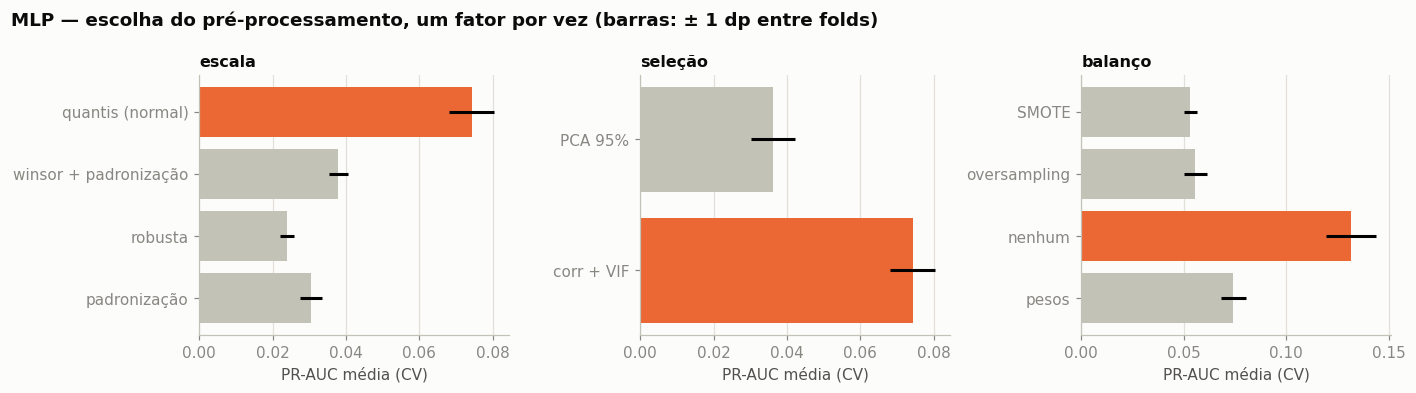

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
filtros = {'escala': etapas['etapa'] == '1-escala',
           'seleção': (etapas['escala'] == ESC) & (etapas['balanço'] == 'pesos'),
           'balanço': (etapas['escala'] == ESC) & (etapas['seleção'] == SEL)}
for ax, fator in zip(axes, ['escala', 'seleção', 'balanço']):
    linhas = etapas[filtros[fator]].drop_duplicates(fator)
    sub = linhas.set_index(fator)['PR-AUC média']
    ax.barh(range(len(sub)), sub.values, xerr=linhas['dp'].values,
            color=[COR['MLP'] if i == PREP[fator] else EIXO for i in sub.index])
    ax.set_yticks(range(len(sub)), sub.index)
    ax.set_title(fator, fontsize=10.5)
    ax.set_xlabel('PR-AUC média (CV)')
    ax.grid(axis='y', visible=False)
fig.suptitle('MLP — escolha do pré-processamento, um fator por vez (barras: ± 1 dp entre folds)',
             x=0.01, ha='left', fontweight='bold', color=TINTA)
plt.tight_layout()

## 3. Busca aleatória de hiperparâmetros (inclui camadas e neurônios)

15 configurações sorteadas, com o pré-processamento da seção 2 fixo e o mesmo treino (até 100 épocas, platô,
paciência 12). Se nenhuma superar a MLP base, fica a base.

In [7]:
espaco = {'n_camadas': [1, 2, 3, 4], 'largura': [64, 128, 256, 512], 'dropout': uniform(0.05, 0.45),
          'lr': loguniform(3e-4, 3e-3), 'wd': loguniform(1e-6, 1e-3), 'lote': [128, 256, 512]}
busca = []
for i, prm in enumerate(ParameterSampler(espaco, n_iter=2 if RAPIDO else 15, random_state=SEMENTE)):
    cfg = {**CFG_BASE, **{k: (int(v) if k in ('n_camadas', 'largura', 'lote') else float(v)) for k, v in prm.items()}}
    P, infos, _ = rodar(cfg, PREP, etapa='busca de hiperparâmetros', nome=f'config {i + 1}')
    media, dp = metricas_cv(y_tr, P, DIV)
    busca.append({**{k: cfg[k] for k in espaco}, 'camadas': '-'.join(map(str, camadas_funil(cfg['largura'], cfg['n_camadas']))),
                  'PR-AUC média': media['PR-AUC média'], 'dp': dp['PR-AUC média'], 'ROC-AUC média': media['ROC-AUC média'],
                  'PR-AUC faliu': media['PR-AUC faliu'], 'Log loss': media['Log loss (multiclasse)'],
                  'épocas (média)': np.mean([x['épocas rodadas'] for x in infos])})
    print(f'{i + 1:2d}: {busca[-1]["camadas"]:<16} dropout {cfg["dropout"]:.2f} lr {cfg["lr"]:.1e} lote {cfg["lote"]:<4} '
          f'PR-AUC média = {media["PR-AUC média"]:.4f} | decorrido {minutos():.1f} min')
busca = pd.DataFrame(busca).sort_values('PR-AUC média', ascending=False).reset_index(drop=True)
base_prep = etapas['PR-AUC média'].max()
print(f'MLP base (256-128-64) com o melhor pré-processamento: {base_prep:.4f}')
busca.round(4)

 1: 64               dropout 0.22 lr 1.6e-03 lote 512  PR-AUC média = 0.0929 | decorrido 0.1 min
 2: 256              dropout 0.25 lr 8.6e-04 lote 512  PR-AUC média = 0.0977 | decorrido 0.1 min


 3: 128-64-32-16     dropout 0.37 lr 2.8e-03 lote 128  PR-AUC média = 0.1133 | decorrido 0.1 min
 4: 512-256          dropout 0.05 lr 1.2e-03 lote 128  PR-AUC média = 0.1070 | decorrido 0.1 min


 5: 64-32            dropout 0.24 lr 1.2e-03 lote 512  PR-AUC média = 0.1141 | decorrido 0.1 min
 6: 256-128          dropout 0.49 lr 3.7e-04 lote 256  PR-AUC média = 0.1157 | decorrido 0.1 min


 7: 512-256-128      dropout 0.28 lr 3.3e-04 lote 128  PR-AUC média = 0.1266 | decorrido 0.1 min
 8: 128-64           dropout 0.25 lr 2.8e-03 lote 128  PR-AUC média = 0.1291 | decorrido 0.1 min


 9: 128-64-32-16     dropout 0.06 lr 1.4e-03 lote 512  PR-AUC média = 0.1278 | decorrido 0.1 min
10: 128-64-32-16     dropout 0.07 lr 5.4e-04 lote 128  PR-AUC média = 0.1298 | decorrido 0.1 min


11: 128              dropout 0.24 lr 1.1e-03 lote 256  PR-AUC média = 0.0969 | decorrido 0.1 min
12: 128-64           dropout 0.40 lr 2.4e-03 lote 256  PR-AUC média = 0.1334 | decorrido 0.1 min


13: 128-64           dropout 0.20 lr 1.0e-03 lote 512  PR-AUC média = 0.1191 | decorrido 0.1 min
14: 128-64           dropout 0.22 lr 2.0e-03 lote 512  PR-AUC média = 0.1268 | decorrido 0.1 min


15: 64               dropout 0.32 lr 5.9e-04 lote 128  PR-AUC média = 0.0901 | decorrido 0.1 min
MLP base (256-128-64) com o melhor pré-processamento: 0.1317


,n_camadas,largura,dropout,lr,wd,lote,camadas,PR-AUC média,dp,ROC-AUC média,PR-AUC faliu,Log loss,épocas (média)
0,2,128,0.3988,0.0024,0.0002,256,128-64,0.1334,0.0111,0.8879,0.5429,0.1980,49.6
1,4,128,0.0655,0.0005,0.0002,128,128-64-32-16,0.1298,0.0115,0.8805,0.5297,0.2015,39.4
2,2,128,0.2527,0.0028,0.0000,128,128-64,0.1291,0.0089,0.8863,0.5437,0.1991,36.0
3,4,128,0.0572,0.0014,0.0000,512,128-64-32-16,0.1278,0.0046,0.8791,0.5267,0.2036,44.8
4,2,128,0.2249,0.0020,0.0008,512,128-64,0.1268,0.0192,0.8763,0.5202,0.2017,32.2
5,3,512,0.2814,0.0003,0.0001,128,512-256-128,0.1266,0.0112,0.8889,0.5405,0.1973,33.2
6,2,128,0.1969,0.0010,0.0000,512,128-64,0.1191,0.0109,0.8721,0.5076,0.2041,34.0
7,2,256,0.4882,0.0004,0.0000,256,256-128,0.1157,0.0067,0.8735,0.5030,0.2063,63.2
8,2,64,0.2444,0.0012,0.0000,512,64-32,0.1141,0.0037,0.8681,0.4926,0.2060,36.2
9,4,128,0.3686,0.0028,0.0007,128,128-64-32-16,0.1133,0.0050,0.8904,0.5427,0.2011,45.6


In [8]:
# Efeito do número de camadas, da largura e do lote (melhor e média da PR-AUC entre as configurações sorteadas)
display(pd.concat({f: busca.groupby(f)['PR-AUC média'].agg(['max', 'mean', 'size'])
                   for f in ['n_camadas', 'largura', 'lote']}).round(4))
if busca.loc[0, 'PR-AUC média'] >= base_prep:
    CFG_BUSCA = {**CFG_BASE, **{k: busca.loc[0, k] for k in espaco}}
else:
    CFG_BUSCA = dict(CFG_BASE)
CFG_BUSCA = {k: (int(v) if k in ('n_camadas', 'largura', 'lote', 'max_epocas', 'paciencia') else
                 (float(v) if isinstance(v, (float, np.floating)) else v)) for k, v in CFG_BUSCA.items()}
print('configuração escolhida na busca:', CFG_BUSCA, '| camadas:', camadas_funil(CFG_BUSCA['largura'], CFG_BUSCA['n_camadas']))

max    mean  size
n_camadas 1    0.0977  0.0944     4
          2    0.1334  0.1207     7
          3    0.1266  0.1266     1
          4    0.1298  0.1237     3
largura   64   0.1141  0.0990     3
          128  0.1334  0.1220     8
          256  0.1157  0.1067     2
          512  0.1266  0.1168     2
lote      128  0.1298  0.1160     6
          256  0.1334  0.1153     3
          512  0.1278  0.1131     6

configuração escolhida na busca: {'n_camadas': 2, 'largura': 128, 'dropout': 0.39880977051250155, 'lr': 0.002354770601447807, 'wd': 0.00015199034037054093, 'lote': 256, 'agenda': 'plato', 'max_epocas': 100, 'paciencia': 12} | camadas: [128, 64]


## 4. Treino longo: épocas, agenda da taxa de aprendizado e regularização

Até aqui a rede treina **no máximo 100 épocas**, com a taxa caindo pela metade a cada 4 épocas sem melhora e parada
antecipada. Testamos se **treinar por muito mais tempo** (1.000, 2.000 e 5.000 épocas) melhora o resultado, partindo
da configuração da busca:

- **agenda da taxa**: platô, constante ou **cosseno** (a taxa cai suavemente até quase zero ao longo de todas as
  épocas, o que faz cada época extra ser usada de fato);
- **regularização mais forte**: *dropout* 0,5 e *weight decay* $10^{-3}$ (ou $10^{-2}$), e uma rede com o dobro de
  neurônios por camada;
- em todos os casos, a rede guarda os pesos da **melhor época na validação interna**;
- para os gráficos, registramos época a época a PR-AUC média no fold de validação da CV. Ela só aparece na curva;
  nenhuma escolha usa esse número.

In [9]:
NUCLEO = {k: CFG_BUSCA[k] for k in ['n_camadas', 'largura', 'dropout', 'lr', 'wd', 'lote']}
REG = dict(dropout=0.5, wd=1e-3)
LARGA = dict(largura=min(2 * NUCLEO['largura'], 1024))
BASE_NOME = 'escolhida na busca (até 100 épocas)'
EXPERIMENTOS = [
    (BASE_NOME, dict(agenda='plato', max_epocas=ep(100), paciencia=12), False),
    ('platô, até 5.000 épocas, paciência 100', dict(agenda='plato', max_epocas=ep(5000), paciencia=100), False),
    ('platô, 1.000 sem parada', dict(agenda='plato', max_epocas=ep(1000), paciencia=None), True),
    ('constante, 1.000 sem parada', dict(agenda='constante', max_epocas=ep(1000), paciencia=None), True),
    ('cosseno 1.000', dict(agenda='cosseno', max_epocas=ep(1000), paciencia=None), True),
    ('cosseno 1.000 + regularização', dict(agenda='cosseno', max_epocas=ep(1000), paciencia=None, **REG), True),
    ('cosseno 2.000', dict(agenda='cosseno', max_epocas=ep(2000), paciencia=None), True),
    ('cosseno 2.000 + regularização', dict(agenda='cosseno', max_epocas=ep(2000), paciencia=None, **REG), True),
    ('cosseno 2.000, taxa 3e-4', dict(agenda='cosseno', max_epocas=ep(2000), paciencia=None, lr=3e-4), True),
    ('cosseno 5.000', dict(agenda='cosseno', max_epocas=ep(5000), paciencia=None), True),
    ('cosseno 1.000 + regularização forte', dict(agenda='cosseno', max_epocas=ep(1000), paciencia=None,
                                                 dropout=0.5, wd=1e-2), True),
    ('cosseno 1.000, rede larga + regularização', dict(agenda='cosseno', max_epocas=ep(1000), paciencia=None,
                                                       **LARGA, **REG), True),
    ('cosseno 300, rede larga + regularização', dict(agenda='cosseno', max_epocas=ep(300), paciencia=None,
                                                     **LARGA, **REG), True),
    ('cosseno 5.000 + regularização', dict(agenda='cosseno', max_epocas=ep(5000), paciencia=None, **REG), True),
]
CFG = {nome: {**NUCLEO, **mud} for nome, mud, _ in EXPERIMENTOS}
RES, CURVAS, PAREDE = {}, {}, {}
for nome, _, registrar in EXPERIMENTOS:
    P, infos, curvas = rodar(CFG[nome], PREP, registrar=registrar, etapa='treino longo', nome=nome)
    RES[nome], PAREDE[nome] = (P, infos), CUSTO[-1]['minutos']
    if curvas:
        CURVAS[nome] = pd.DataFrame(curvas)
    media, _ = metricas_cv(y_tr, P, DIV)
    print(f'{nome:<44} PR-AUC média (CV) = {media["PR-AUC média"]:.4f} | melhor época (média) '
          f'{np.mean([i["época da melhor"] for i in infos]):7.1f} | {PAREDE[nome]:5.1f} min | decorrido {minutos():6.1f} min')

escolhida na busca (até 100 épocas)          PR-AUC média (CV) = 0.1334 | melhor época (média)    37.6 |   0.5 min | decorrido    0.1 min


platô, até 5.000 épocas, paciência 100       PR-AUC média (CV) = 0.1372 | melhor época (média)   104.2 |   2.3 min | decorrido    0.1 min


platô, 1.000 sem parada                      PR-AUC média (CV) = 0.1372 | melhor época (média)   244.6 |   8.6 min | decorrido    0.1 min
constante, 1.000 sem parada                  PR-AUC média (CV) = 0.1299 | melhor época (média)    55.8 |   8.7 min | decorrido    0.1 min


cosseno 1.000                                PR-AUC média (CV) = 0.1326 | melhor época (média)    49.0 |   9.1 min | decorrido    0.1 min
cosseno 1.000 + regularização                PR-AUC média (CV) = 0.1329 | melhor época (média)    79.8 |   8.9 min | decorrido    0.1 min


cosseno 2.000                                PR-AUC média (CV) = 0.1352 | melhor época (média)    51.0 |  17.8 min | decorrido    0.1 min
cosseno 2.000 + regularização                PR-AUC média (CV) = 0.1329 | melhor época (média)    79.4 |  17.9 min | decorrido    0.1 min


cosseno 2.000, taxa 3e-4                     PR-AUC média (CV) = 0.1292 | melhor época (média)   207.0 |  17.9 min | decorrido    0.1 min


cosseno 5.000                                PR-AUC média (CV) = 0.1373 | melhor época (média)    45.4 |  44.5 min | decorrido    0.1 min
cosseno 1.000 + regularização forte          PR-AUC média (CV) = 0.1326 | melhor época (média)    78.4 |   9.1 min | decorrido    0.1 min


cosseno 1.000, rede larga + regularização    PR-AUC média (CV) = 0.1276 | melhor época (média)    48.8 |   9.3 min | decorrido    0.1 min
cosseno 300, rede larga + regularização      PR-AUC média (CV) = 0.1299 | melhor época (média)    47.0 |   2.8 min | decorrido    0.1 min


cosseno 5.000 + regularização                PR-AUC média (CV) = 0.1303 | melhor época (média)   331.4 |  43.5 min | decorrido    0.1 min


### 4.1 Comparação na validação cruzada (1 semente)

**Δ vs base** é a diferença média por fold em relação à configuração da busca, e **folds melhores** conta em quantos
dos 5 folds o experimento a superou (os folds são os mesmos: comparação pareada).

In [10]:
pr_fold = {n: np.array([metricas(y_tr[iva], RES[n][0][iva])['PR-AUC média'] for _, iva in DIV]) for n in RES}
linhas = []
for nome, (P, infos) in RES.items():
    c = CFG[nome]
    media, dp = metricas_cv(y_tr, P, DIV)
    d = pr_fold[nome] - pr_fold[BASE_NOME]
    linhas.append({
        'experimento': nome, 'agenda': c['agenda'], 'épocas máx.': c['max_epocas'],
        'paciência': c['paciencia'] if c.get('paciencia') else '—', 'camadas': '-'.join(map(str, camadas_funil(c['largura'], c['n_camadas']))),
        'dropout': c['dropout'], 'wd': c['wd'], 'taxa': c['lr'],
        'melhor época (média)': np.mean([i['época da melhor'] for i in infos]),
        'épocas rodadas (média)': np.mean([i['épocas rodadas'] for i in infos]),
        'PR-AUC média': media['PR-AUC média'], 'dp': dp['PR-AUC média'],
        'Δ vs base': d.mean(), 'folds melhores': int((d > 0).sum()),
        'ROC-AUC média': media['ROC-AUC média'], 'PR-AUC faliu': media['PR-AUC faliu'],
        'Log loss': media['Log loss (multiclasse)'], 'minutos': PAREDE[nome]})
tab = pd.DataFrame(linhas).set_index('experimento')
tab.round(4)

,agenda,épocas máx.,paciência,camadas,dropout,wd,taxa,melhor época (média),épocas rodadas (média),PR-AUC média,dp,Δ vs base,folds melhores,ROC-AUC média,PR-AUC faliu,Log loss,minutos
experimento,,,,,,,,,,,,,,,,,
escolhida na busca (até 100 épocas),plato,100,12,128-64,0.3988,0.0002,0.0024,37.6,49.6,0.1334,0.0111,0.0000,0,0.8879,0.5429,0.1980,0.5268
"platô, até 5.000 épocas, paciência 100",plato,5000,100,128-64,0.3988,0.0002,0.0024,104.2,204.2,0.1372,0.0133,0.0039,2,0.8900,0.5493,0.1977,2.3146
"platô, 1.000 sem parada",plato,1000,—,128-64,0.3988,0.0002,0.0024,244.6,1000.0,0.1372,0.0133,0.0039,2,0.8900,0.5495,0.1977,8.6024
"constante, 1.000 sem parada",constante,1000,—,128-64,0.3988,0.0002,0.0024,55.8,1000.0,0.1299,0.0116,-0.0035,2,0.8901,0.5493,0.2002,8.7199
cosseno 1.000,cosseno,1000,—,128-64,0.3988,0.0002,0.0024,49.0,1000.0,0.1326,0.0071,-0.0008,2,0.8905,0.5517,0.1978,9.0964
cosseno 1.000 + regularização,cosseno,1000,—,128-64,0.5000,0.0010,0.0024,79.8,1000.0,0.1329,0.0151,-0.0005,1,0.8918,0.5542,0.1996,8.8892
cosseno 2.000,cosseno,2000,—,128-64,0.3988,0.0002,0.0024,51.0,2000.0,0.1352,0.0096,0.0018,2,0.8871,0.5493,0.1994,17.8066
cosseno 2.000 + regularização,cosseno,2000,—,128-64,0.5000,0.0010,0.0024,79.4,2000.0,0.1329,0.0066,-0.0005,3,0.8931,0.5574,0.1980,17.9344
"cosseno 2.000, taxa 3e-4",cosseno,2000,—,128-64,0.3988,0.0002,0.0003,207.0,2000.0,0.1292,0.0126,-0.0042,1,0.8904,0.5523,0.1986,17.8741


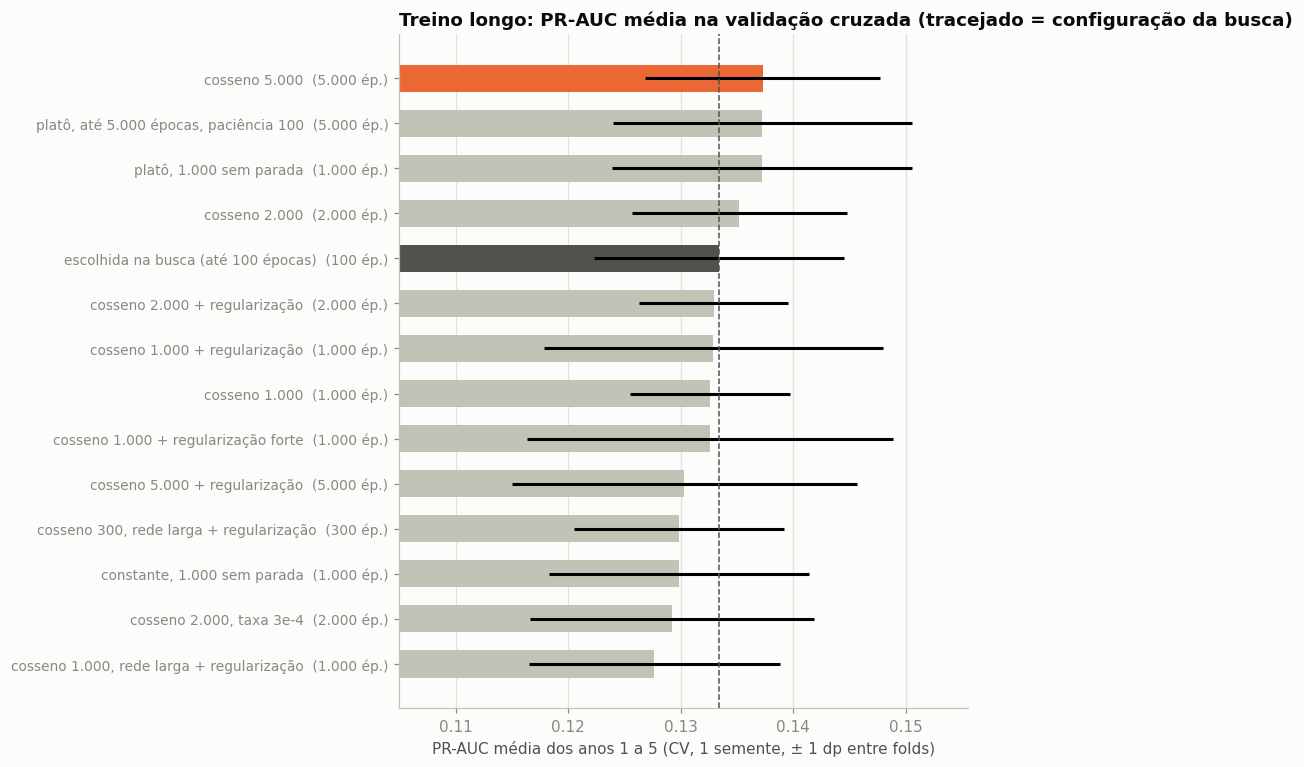

In [11]:
ordem = tab.sort_values('PR-AUC média').index
fig, ax = plt.subplots(figsize=(9, 0.42 * len(ordem) + 1.2))
cores = [COR['MLP'] if n == ordem[-1] else ('#52514e' if n == BASE_NOME else EIXO) for n in ordem]
ax.barh(range(len(ordem)), tab.loc[ordem, 'PR-AUC média'], xerr=tab.loc[ordem, 'dp'], color=cores, height=0.6)
ax.axvline(tab.loc[BASE_NOME, 'PR-AUC média'], color='#52514e', linestyle='--', linewidth=1)
ax.set_yticks(range(len(ordem)), [n + '  (' + f'{tab.loc[n, "épocas máx."]:,}'.replace(',', '.') + ' ép.)' for n in ordem], fontsize=9)
lo = (tab['PR-AUC média'] - tab['dp']).min()
ax.set_xlim(max(0, lo - 0.01), (tab['PR-AUC média'] + tab['dp']).max() + 0.005)
ax.set_xlabel('PR-AUC média dos anos 1 a 5 (CV, 1 semente, ± 1 dp entre folds)')
ax.set_title('Treino longo: PR-AUC média na validação cruzada (tracejado = configuração da busca)')
ax.grid(axis='y', visible=False)
plt.tight_layout()

### 4.2 Curvas de aprendizado

Média dos 5 folds, época a época. **Validação interna**: os 15% do treino que decidem a melhor época. **Fold da CV**:
o fold que o treino nunca vê (só para o gráfico). A perda de treino é a entropia cruzada média da época.

,época do máximo (fold CV),PR-AUC máxima (fold CV),PR-AUC na última época,perda de treino: 1ª → última época
experimento,,,,
"platô, 1.000 sem parada",43,0.1410,0.1386,0.544 → 0.181
"constante, 1.000 sem parada",41,0.1419,0.0981,0.544 → 0.142
cosseno 1.000,36,0.1382,0.0933,0.544 → 0.135
cosseno 1.000 + regularização,59,0.1431,0.1106,0.563 → 0.156
cosseno 2.000,44,0.1383,0.0920,0.544 → 0.131
cosseno 2.000 + regularização,50,0.1457,0.1087,0.563 → 0.153
"cosseno 2.000, taxa 3e-4",101,0.1313,0.1033,1.610 → 0.144
cosseno 5.000,37,0.1412,0.0867,0.544 → 0.129
cosseno 1.000 + regularização forte,50,0.1416,0.1121,0.564 → 0.155


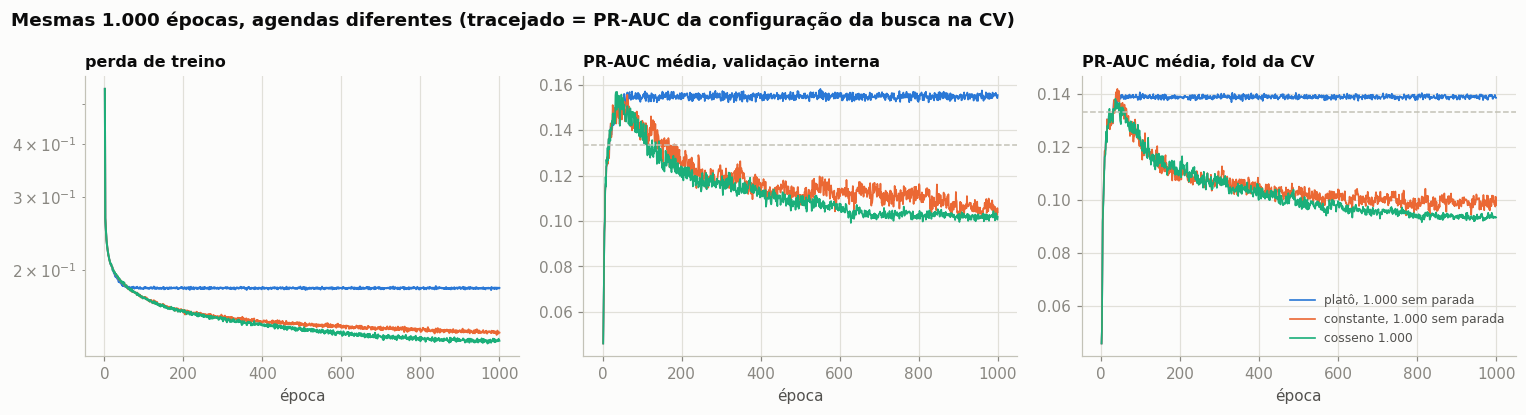

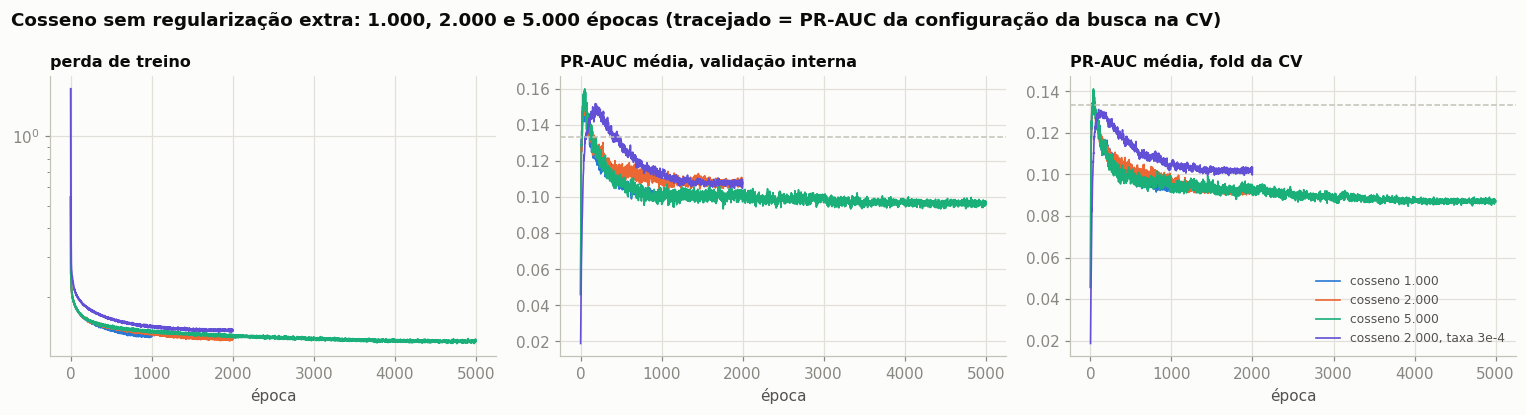

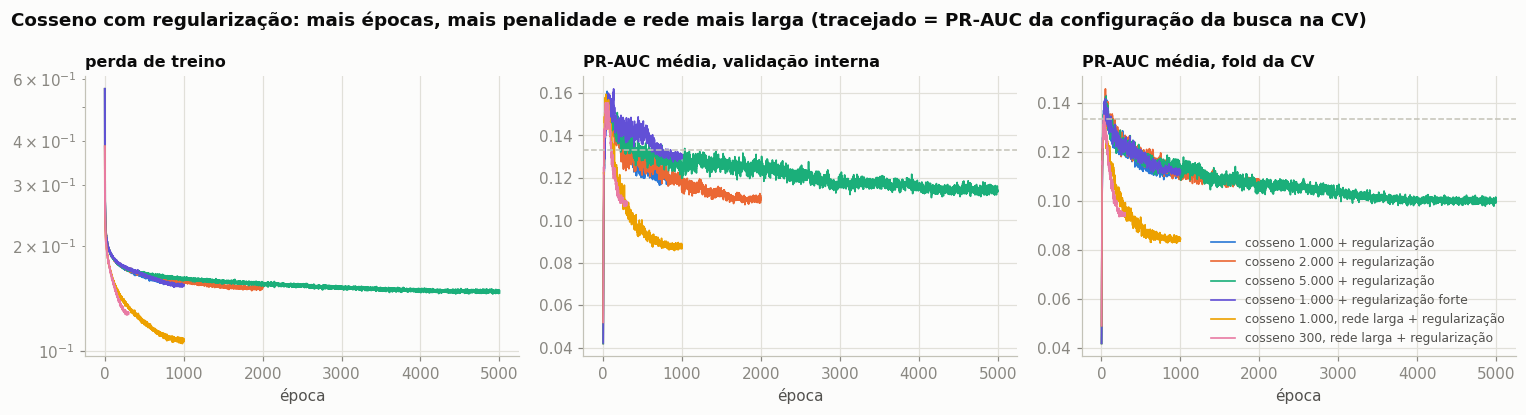

In [12]:
def media_curva(nome):
    return CURVAS[nome].groupby('época')[['perda treino', 'PR-AUC validação interna', 'PR-AUC fold CV', 'taxa']].mean()


grupos = [('Mesmas 1.000 épocas, agendas diferentes',
           ['platô, 1.000 sem parada', 'constante, 1.000 sem parada', 'cosseno 1.000']),
          ('Cosseno sem regularização extra: 1.000, 2.000 e 5.000 épocas',
           ['cosseno 1.000', 'cosseno 2.000', 'cosseno 5.000', 'cosseno 2.000, taxa 3e-4']),
          ('Cosseno com regularização: mais épocas, mais penalidade e rede mais larga',
           ['cosseno 1.000 + regularização', 'cosseno 2.000 + regularização', 'cosseno 5.000 + regularização',
            'cosseno 1.000 + regularização forte', 'cosseno 1.000, rede larga + regularização',
            'cosseno 300, rede larga + regularização'])]
paleta = ['#2a78d6', '#eb6834', '#1baf7a', '#6250d6', '#eda100', '#e87ba4']
for titulo, nomes in grupos:
    nomes = [n for n in nomes if n in CURVAS]
    if not nomes:
        continue
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
    for cor, n in zip(paleta, nomes):
        m = media_curva(n)
        axes[0].plot(m.index, m['perda treino'], color=cor, linewidth=1.3, label=n)
        axes[1].plot(m.index, m['PR-AUC validação interna'], color=cor, linewidth=1.1, label=n)
        axes[2].plot(m.index, m['PR-AUC fold CV'], color=cor, linewidth=1.1, label=n)
    axes[0].set_yscale('log')
    for ax, t in zip(axes, ['perda de treino', 'PR-AUC média, validação interna', 'PR-AUC média, fold da CV']):
        ax.set_title(t, fontsize=10.5)
        ax.set_xlabel('época')
    for ax in axes[1:]:
        ax.axhline(tab.loc[BASE_NOME, 'PR-AUC média'], color=EIXO, linestyle='--', linewidth=1)
    axes[2].legend(fontsize=8, loc='lower right')
    fig.suptitle(titulo + ' (tracejado = PR-AUC da configuração da busca na CV)', x=0.01, ha='left',
                 fontweight='bold', color=TINTA)
    plt.tight_layout()

resumo_curvas = []
for n in CURVAS:
    m = media_curva(n)
    resumo_curvas.append({'experimento': n, 'época do máximo (fold CV)': int(m['PR-AUC fold CV'].idxmax()),
                          'PR-AUC máxima (fold CV)': m['PR-AUC fold CV'].max(),
                          'PR-AUC na última época': m['PR-AUC fold CV'].iloc[-1],
                          'perda de treino: 1ª → última época': f"{m['perda treino'].iloc[0]:.3f} → {m['perda treino'].iloc[-1]:.3f}"})
pd.DataFrame(resumo_curvas).set_index('experimento').round(4)

## 5. Seleção robusta: mais sementes, CV repetida e testes pareados

Com 1 semente e 5 folds, diferenças de 0,005 na PR-AUC média estão dentro do ruído: a semente muda a inicialização,
a ordem dos lotes e a validação interna. Para que a escolha não dependa desse ruído:

1. **Candidatos**: os 3 experimentos de maior PR-AUC média na seção 4, mais a configuração da busca como referência.
   Ficam de fora os que levam mais de `LIMITE_MIN` minutos por CV (os de 5.000 épocas), para o custo caber no
   orçamento; a seção 4 já mostra que eles não ganham dos de 1.000 épocas.
2. **Média de 5 sementes** (as probabilidades das 5 redes são somadas e divididas por 5) em cada fold.
3. **CV repetida 3 × 5**: a mesma CV de 5 folds em 3 divisões diferentes do treino (15 folds no total). A escolha
   final é a maior PR-AUC média nesses 15 folds.
4. **Testes pareados contra o vencedor**, com correção de Holm para as várias comparações:
   - **t corrigido de Nadeau e Bengio** sobre as 15 diferenças por fold: os treinos dos folds se sobrepõem, então a
     variância das diferenças é inflada por $(1/J + n_\text{val}/n_\text{treino}) = (1/15 + 1/4)$;
   - ***bootstrap* pareado por empresa** (1.000 reamostras estratificadas das 34 mil empresas do treino, as mesmas
     para os dois modelos) da PR-AUC média calculada nas previsões fora da amostra de cada repetição.

Se um candidato não difere do vencedor de forma significativa, os dois são equivalentes para este critério; o vencedor
continua sendo o de maior média.

In [13]:
LIMITE_MIN = float(os.environ.get('LIMITE_MIN', '25'))
N_SEM = 2 if RAPIDO else 5
viaveis = tab[(tab['minutos'] <= LIMITE_MIN) | RAPIDO].sort_values('PR-AUC média', ascending=False)
CANDIDATOS = list(dict.fromkeys(viaveis.index[:3].tolist() + [BASE_NOME]))
print('candidatos:', CANDIDATOS)

PM = {}  # PM[nome][r] = média das sementes nas previsões fora da amostra da repetição r
for nome in CANDIDATOS:
    PM[nome] = []
    for r in range(REPETICOES):
        Ps = [rodar(CFG[nome], PREP, semente=s, rep=r, etapa='seleção robusta', nome=nome)[0] for s in range(N_SEM)]
        PM[nome].append(np.mean(Ps, axis=0))
    print(f'{nome:<44} {N_SEM} sementes × {REPETICOES} repetições | decorrido {minutos():6.1f} min')

DIVS = {r: (DIV if r == 0 else folds(y_tr, N_FOLDS, r)) for r in range(REPETICOES)}


def por_fold(nome, met='PR-AUC média'):
    return np.array([metricas(y_tr[iva], PM[nome][r][iva])[met] for r in range(REPETICOES) for _, iva in DIVS[r]])


FOLDS_PR = {n: por_fold(n) for n in CANDIDATOS}
FOLDS_FAL = {n: por_fold(n, 'PR-AUC faliu') for n in CANDIDATOS}
robusta = pd.DataFrame({n: {
    'PR-AUC média (1 semente, divisão principal)': tab.loc[n, 'PR-AUC média'],
    f'PR-AUC média ({N_SEM} sementes, {REPETICOES}×{N_FOLDS} folds)': FOLDS_PR[n].mean(),
    'dp entre os folds': FOLDS_PR[n].std(ddof=1),
    f'PR-AUC faliu ({N_SEM} sementes, {REPETICOES}×{N_FOLDS} folds)': FOLDS_FAL[n].mean(),
    'minutos por CV (1 semente)': tab.loc[n, 'minutos']} for n in CANDIDATOS}).T
robusta = robusta.sort_values(robusta.columns[1], ascending=False)
VENCEDOR = robusta.index[0]
print('vencedor da seleção robusta:', VENCEDOR)
robusta.round(4)

candidatos: ['platô, até 5.000 épocas, paciência 100', 'platô, 1.000 sem parada', 'cosseno 2.000', 'escolhida na busca (até 100 épocas)']
platô, até 5.000 épocas, paciência 100       5 sementes × 3 repetições | decorrido    0.3 min


platô, 1.000 sem parada                      5 sementes × 3 repetições | decorrido    0.3 min


cosseno 2.000                                5 sementes × 3 repetições | decorrido    0.3 min


escolhida na busca (até 100 épocas)          5 sementes × 3 repetições | decorrido    0.3 min


vencedor da seleção robusta: cosseno 2.000


,"PR-AUC média (1 semente, divisão principal)","PR-AUC média (5 sementes, 3×5 folds)",dp entre os folds,"PR-AUC faliu (5 sementes, 3×5 folds)",minutos por CV (1 semente)
cosseno 2.000,0.1352,0.1451,0.0077,0.5701,17.8066
"platô, 1.000 sem parada",0.1372,0.1412,0.0107,0.5549,8.6024
"platô, até 5.000 épocas, paciência 100",0.1372,0.1405,0.0102,0.5537,2.3146
escolhida na busca (até 100 épocas),0.1334,0.1394,0.0090,0.5476,0.5268


In [14]:
def pr_media_reps(y, Pr):
    """PR-AUC média dos anos 1 a 5, calculada em cada repetição (Pr: empresas × repetições × classes) e promediada."""
    return np.mean([np.mean([average_precision_score((y == h).astype(int), Pr[:, r, h]) for h in HORIZONTES])
                    for r in range(Pr.shape[1])])


AMOSTRAS = amostras_bootstrap(y_tr, 100 if RAPIDO else 1000, semente=SEMENTE)
PR_V = np.stack(PM[VENCEDOR], axis=1)
linhas = []
for n in CANDIDATOS:
    if n == VENCEDOR:
        continue
    dif, t, p_t, gl = t_corrigido(FOLDS_PR[VENCEDOR] - FOLDS_PR[n], 1 / (N_FOLDS - 1))
    b = bootstrap_pareado(pr_media_reps, y_tr, PR_V, np.stack(PM[n], axis=1), AMOSTRAS)
    linhas.append({'candidato': n, 'vencedor − candidato (média dos folds)': dif,
                   'folds em que o vencedor é melhor': f'{int((FOLDS_PR[VENCEDOR] > FOLDS_PR[n]).sum())} de {len(FOLDS_PR[n])}',
                   't corrigido': t, 'p (t corrigido)': p_t,
                   'Δ bootstrap (OOF)': b['diferença'], 'IC 95% inf.': b['IC 95% inf.'], 'IC 95% sup.': b['IC 95% sup.'],
                   'p (bootstrap)': b['p (bootstrap)']})
testes_sel = pd.DataFrame(linhas).set_index('candidato')
if len(testes_sel):
    testes_sel['p Holm (t corrigido)'] = holm(testes_sel['p (t corrigido)'])
    testes_sel['p Holm (bootstrap)'] = holm(testes_sel['p (bootstrap)'])
    testes_sel['diferença significativa (5%)?'] = np.where(
        (testes_sel['p Holm (t corrigido)'] < 0.05) & (testes_sel['p Holm (bootstrap)'] < 0.05), 'sim', 'não')
testes_sel.round(4)

,vencedor − candidato (média dos folds),folds em que o vencedor é melhor,t corrigido,p (t corrigido),Δ bootstrap (OOF),IC 95% inf.,IC 95% sup.,p (bootstrap),p Holm (t corrigido),p Holm (bootstrap),diferença significativa (5%)?
candidato,,,,,,,,,,,
"platô, até 5.000 épocas, paciência 100",0.0045,10 de 15,1.1176,0.2825,0.0030,-0.0007,0.0066,0.130,0.5651,0.260,não
"platô, 1.000 sem parada",0.0039,10 de 15,0.8610,0.4037,0.0026,-0.0010,0.0061,0.188,0.5651,0.260,não
escolhida na busca (até 100 épocas),0.0056,12 de 15,1.5656,0.1398,0.0038,-0.0005,0.0080,0.086,0.4193,0.258,não


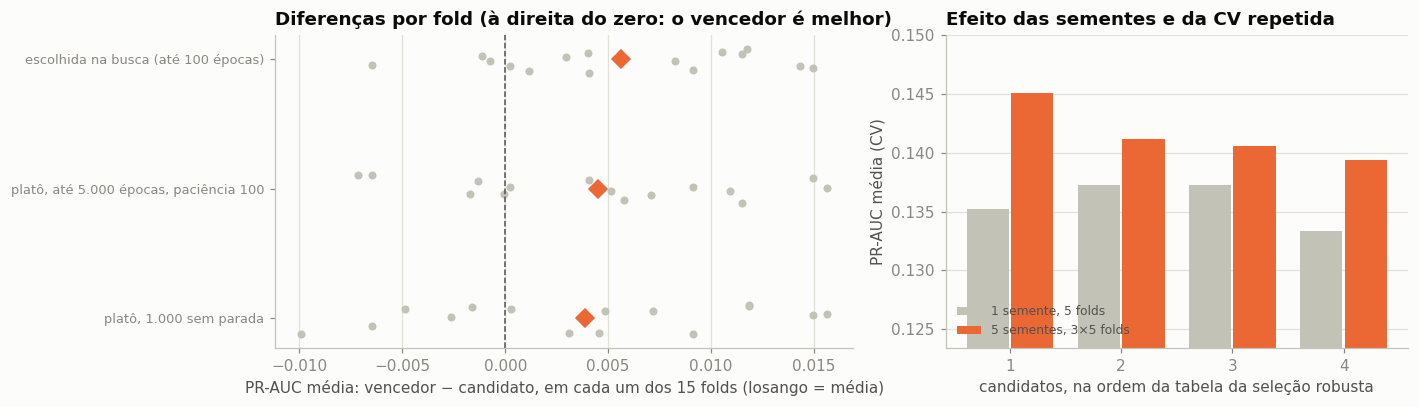

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [1.25, 1]})
outros = [n for n in robusta.index if n != VENCEDOR]
for k, n in enumerate(outros):
    d = FOLDS_PR[VENCEDOR] - FOLDS_PR[n]
    axes[0].scatter(d, np.full(len(d), k) + np.random.default_rng(k).uniform(-0.12, 0.12, len(d)), s=18,
                    color=EIXO, zorder=2)
    axes[0].plot([d.mean()], [k], marker='D', color=COR['MLP'], markersize=8, zorder=3)
axes[0].axvline(0, color=TINTA2, linestyle='--', linewidth=1)
axes[0].set_yticks(range(len(outros)), outros, fontsize=8.5)
axes[0].set_xlabel('PR-AUC média: vencedor − candidato, em cada um dos 15 folds (losango = média)')
axes[0].set_title('Diferenças por fold (à direita do zero: o vencedor é melhor)')
axes[0].grid(axis='y', visible=False)

x = np.arange(len(robusta))
um = robusta.iloc[:, 0].values
cinco = robusta.iloc[:, 1].values
axes[1].bar(x - 0.2, um, width=0.38, color=EIXO, label='1 semente, 5 folds')
axes[1].bar(x + 0.2, cinco, width=0.38, color=COR['MLP'], label=f'{N_SEM} sementes, {REPETICOES}×{N_FOLDS} folds')
axes[1].set_xticks(x, [f'{i + 1}' for i in x])
axes[1].set_ylim(min(um.min(), cinco.min()) - 0.01, max(um.max(), cinco.max()) + 0.005)
axes[1].set_xlabel('candidatos, na ordem da tabela da seleção robusta')
axes[1].set_ylabel('PR-AUC média (CV)')
axes[1].set_title('Efeito das sementes e da CV repetida')
axes[1].legend(fontsize=8, loc='lower left')
axes[1].grid(axis='x', visible=False)
plt.tight_layout()

## 6. Modelo final e avaliação única no teste

A configuração vencedora da seção 5 é treinada em **todo o treino** com 5 sementes (média das probabilidades) e
avaliada **uma única vez** no teste. *Treino* = métricas dentro da amostra; *validação* = previsões fora da amostra
da divisão principal da CV (média de 5 sementes); *teste* = 20% separados no início. A comparação com a regressão
logística, com os testes estatísticos, está no notebook 05.

In [16]:
CFG_FINAL = CFG[VENCEDOR]
SEMENTES_FINAL = list(range(N_SEM))
arq_final = CACHE / f'final_{chave(CFG_FINAL, PREP, DIV, SEMENTES_FINAL)}.npz'
if arq_final.exists():
    with np.load(arq_final) as z:
        P_tr, P_te, info_final, t_final = z['P_tr'], z['P_te'], json.loads(str(z['info'])), float(z['parede'])
else:
    t0 = time.time()
    P_tr, P_te, info_final = final(CFG_FINAL, PREP, X_tr, y_tr, X_te, SEMENTES_FINAL)
    t_final = time.time() - t0
    np.savez_compressed(arq_final, P_tr=P_tr, P_te=P_te, info=json.dumps(info_final), parede=t_final)
CUSTO.append({'etapa': 'modelo final', 'experimento': VENCEDOR, 'semente': len(SEMENTES_FINAL), 'repetição': 0,
              'minutos': t_final / 60})
P_oof = PM[VENCEDOR][0]
n_var = info_final[0]['variáveis']
N_PARAM = n_parametros(CFG_FINAL, n_var)
print(f'modelo final: {VENCEDOR} | {camadas_funil(CFG_FINAL["largura"], CFG_FINAL["n_camadas"])} | '
      f'{n_var} entradas | {N_PARAM:,} parâmetros | {len(info_final)} sementes | {t_final / 60:.1f} min')
display(pd.DataFrame(info_final).round(4))

COLS = ['PR-AUC média', 'ROC-AUC média', 'Recall@FPR5% médio', 'PR-AUC faliu', 'ROC-AUC faliu', 'Recall@FPR5% faliu',
        'Log loss (multiclasse)', 'Brier (multiclasse)', 'PR-AUC ano 1', 'PR-AUC ano 5']
media, _ = metricas_cv(y_tr, P_oof, DIV)
linhas = [{'modelo': 'MLP', 'conjunto': conj, **{k: met[k] for k in COLS}}
          for conj, met in [('treino', metricas(y_tr, P_tr)), ('validação (CV)', media), ('teste', metricas(y_te, P_te))]]
tvt = pd.DataFrame(linhas).set_index(['modelo', 'conjunto'])
tvt.round(4)

modelo final: cosseno 2.000 | [128, 64] | 24 entradas | 12,230 parâmetros | 5 sementes | 22.3 min


,semente,época da melhor,épocas rodadas,PR-AUC validação interna,segundos,variáveis
0,0,202,2000,0.1462,1323.7391,24
1,1,25,2000,0.1608,1320.3006,25
2,2,20,2000,0.1530,1317.8711,25
3,3,30,2000,0.1671,1320.1475,26
4,4,37,2000,0.1520,1312.7395,25


PR-AUC média  ROC-AUC média  Recall@FPR5% médio  PR-AUC faliu  ROC-AUC faliu  Recall@FPR5% faliu  Log loss (multiclasse)  Brier (multiclasse)  PR-AUC ano 1  PR-AUC ano 5
modelo conjunto                                                                                                                                                                                 
MLP    treino                0.2219         0.9546              0.7394        0.7180         0.9596              0.7587                  0.1616               0.0680        0.2738        0.2261
       validação (CV)        0.1439         0.9005              0.5345        0.5723         0.9154              0.5864                  0.1912               0.0744        0.1697        0.1311
       teste                 0.1323         0.9083              0.5397        0.5759         0.9225              0.5827                  0.1878               0.0743        0.1596        0.1159

## 7. Custo computacional

Minutos de GPU de cada etapa (com os 5 folds em paralelo). Inclui o tempo original das validações cruzadas lidas do cache.

In [17]:
custo = pd.DataFrame(CUSTO)
custo_etapa = custo.groupby('etapa', sort=False)['minutos'].agg(['sum', 'size']).rename(
    columns={'sum': 'minutos de GPU', 'size': 'validações cruzadas / ajustes'})
custo_etapa.loc['total'] = custo_etapa.sum()
print(f'GPU: {GPU} | este notebook (com cache): {minutos():.1f} min')
custo_etapa.round(1)

GPU: NVIDIA GeForce GTX 1650 | este notebook (com cache): 30.3 min


,minutos de GPU,validações cruzadas / ajustes
etapa,,
pré-processamento,4.2,8.0
busca de hiperparâmetros,8.8,15.0
treino longo,201.1,14.0
seleção robusta,426.2,60.0
modelo final,22.3,1.0
total,662.6,98.0


## 8. Salvando

In [18]:
etapas.to_csv('resultados/mlp_preprocessamento.csv', encoding='utf-8-sig', index=False)
busca.to_csv('resultados/busca_mlp.csv', encoding='utf-8-sig', index=False)
tab.to_csv('resultados/mlp_treino_longo.csv', encoding='utf-8-sig')
pd.concat({n: c for n, c in CURVAS.items()}, names=['experimento', 'linha']).to_csv('resultados/mlp_curvas.csv', encoding='utf-8-sig')
robusta.to_csv('resultados/mlp_selecao_robusta.csv', encoding='utf-8-sig')
testes_sel.to_csv('resultados/mlp_testes_selecao.csv', encoding='utf-8-sig')
tvt.to_csv('resultados/treino_validacao_teste_04.csv', encoding='utf-8-sig')
custo.to_csv('resultados/mlp_custo.csv', encoding='utf-8-sig', index=False)
salvar_previsoes('mlp', P_oof=P_oof, P_tr=P_tr, P_te=P_te)
salvar_previsoes('mlp_rep', P_oof=np.stack(PM[VENCEDOR]))  # repetições × empresas × classes (para o notebook 05)
salvar_json('config_04', {
    'MLP': {**PREP, **CFG_FINAL, 'experimento': VENCEDOR,
            'camadas': camadas_funil(CFG_FINAL['largura'], CFG_FINAL['n_camadas']),
            'entradas': n_var, 'parâmetros': N_PARAM, 'sementes': len(SEMENTES_FINAL)},
    'candidatos': CANDIDATOS, 'dispositivo': GPU,
    'tempo_min': custo_etapa['minutos de GPU'].drop('total').to_dict()})
print('ok')

ok


## Conclusões

- **Pré-processamento:** como na logística, venceram **quantis (normal) + correlação + VIF + sem reamostragem**.
  A escala por quantis faz a maior diferença (PR-AUC média 0,074 contra 0,024–0,038 das outras escalas, com pesos de
  classe); o PCA caiu para 0,036. Não reamostrar subiu a PR-AUC média de 0,074 (pesos) para **0,132**;
  oversampling e SMOTE ficaram em 0,056 e 0,053.
- **Arquitetura (busca aleatória):** a melhor configuração tem **2 camadas (128 → 64)**, *dropout* 0,40, *weight
  decay* 1,5 × 10⁻⁴, taxa 2,4 × 10⁻³ e lote 256: 24 entradas e 12.230 parâmetros. Redes mais fundas (4 camadas) ou
  mais largas não ganharam.
- **Treino longo:** treinar mais quase não muda nada. A melhor época (média dos folds) fica entre ~40 e ~330, mesmo com
  limite de 5.000 épocas. Os 14 experimentos ficaram entre 0,128 e 0,137 de PR-AUC média, contra 0,133 da
  configuração da busca (até 100 épocas), dentro do ruído entre folds (dp ≈ 0,01). Regularização mais forte e rede
  mais larga não ajudaram.
- **Seleção robusta (5 sementes × CV repetida 3 × 5):** a média de 5 sementes sobe a PR-AUC média de ~0,135 para
  ~0,14. Venceu **cosseno, 2.000 épocas** (0,145; PR-AUC "faliu" 0,570), mas a vantagem sobre os outros três
  candidatos (0,004–0,006) **não é significativa** (t corrigido: p de Holm ≥ 0,41; *bootstrap*: p de Holm ≥ 0,25).
  Na prática, a configuração da busca com 100 épocas, 34 vezes mais barata, entrega quase o mesmo resultado.
- **Desempenho do modelo final (média de 5 sementes):** PR-AUC média por ano 0,144 na validação e 0,132 no teste;
  PR-AUC "faliu" 0,572 e 0,576; ROC-AUC "faliu" 0,92. O treino (0,22 e 0,72) fica bem acima: há sobreajuste, mas a
  validação escolhida pela CV prevê bem o teste.
- **Custo:** cerca de 11 h de GPU (GTX 1650), das quais 7 h na seleção robusta e 3,4 h no treino longo.